# 05. Campaign and Coupon Analysis

This notebook answers the project's question for this stage: do coupon
campaigns produce a measurable change in targeted households' spending, or
would spending look the same without them?

Two comparison designs are used first, each with a weakness the other covers:

- **Within-household (pre vs. during):** each targeted household's average
  daily spend in a window before the campaign is compared to its spend during
  the campaign window. This controls for baseline differences between
  households (a big spender stays a big spender in both periods), but is
  vulnerable to general time trends unrelated to the campaign, a spending
  increase could simply reflect seasonality, not the campaign itself.
- **Between-household (targeted vs. non-targeted):** targeted households'
  spend during the campaign window is compared to non-targeted households'
  spend in that same window. This controls for time trends (both groups
  experience the same calendar period), but is vulnerable to selection bias,
  if campaigns weren't randomly assigned (unknown here, and unlikely in a real
  retail setting), targeted households may have already been different from
  non-targeted ones before the campaign even started.

Section 4.2 then combines the two into a difference-in-differences comparison:
the change in targeted households' spend minus the change in non-targeted
households' spend over the same two windows. That removes both the stable
baseline gap between the groups and any time trend they share, which is what
neither design manages alone.

One limitation applies to every design here and is not corrected for: a household can be targeted by more than one campaign, and campaign windows for the same household can overlap. When they do, a campaign's "pre" baseline or "during" window can include days actually influenced by a *different* concurrent campaign, and a household counted as non-targeted for one campaign may be inside another campaign's window. This is documented here rather than fixed, since excluding every overlapping day would need a substantially different design.

## 1. Environment Setup and Campaign Participation Base

We connect to PostgreSQL and build the base table: which households were
targeted by which campaigns, and each campaign's day window
(`start_day`/`end_day`, already validated in `01_data_setup_and_loading.ipynb`,
Section 3.4). The cell also fails fast if a required `.env` variable is missing or the base tables are empty, and fetches the dataset's last available `day` once, since two of this notebook's queries need it to keep a campaign window from silently extending past the data that actually exists (Section 1.1).

In [1]:
import os

import numpy as np
import pandas as pd
from dotenv import load_dotenv
from scipy import stats
from sqlalchemy import create_engine, text
from sqlalchemy.engine import URL
from statsmodels.stats.multitest import multipletests

import matplotlib.pyplot as plt

load_dotenv()

DB_HOST = os.getenv("DB_HOST")
DB_PORT = os.getenv("DB_PORT")
DB_NAME = os.getenv("DB_NAME")
DB_USER = os.getenv("DB_USER")
DB_PASSWORD = os.getenv("DB_PASSWORD")

required = {"DB_HOST": DB_HOST, "DB_PORT": DB_PORT, "DB_NAME": DB_NAME,
            "DB_USER": DB_USER, "DB_PASSWORD": DB_PASSWORD}
missing = [name for name, value in required.items() if not value]
if missing:
    raise EnvironmentError(f"Missing variables in .env: {missing}")

engine = create_engine(
    URL.create(
        drivername="postgresql+psycopg2",
        username=DB_USER,
        password=DB_PASSWORD,
        host=DB_HOST,
        port=int(DB_PORT),
        database=DB_NAME,
    )
)

with engine.connect() as conn:
    for table_name in ("transaction_data", "campaign_table", "campaign_desc"):
        n_rows = conn.execute(text(f"SELECT COUNT(*) FROM {table_name}")).scalar()
        if n_rows == 0:
            raise RuntimeError(
                f"{table_name} is empty. Run 01_data_setup_and_loading.ipynb before this notebook."
            )
    max_day = conn.execute(text("SELECT MAX(day) FROM transaction_data")).scalar()

print(f"Last available day in transaction_data: {max_day}")

campaign_base_query = """
SELECT
    ct.household_key,
    ct.campaign,
    cd.start_day,
    cd.end_day,
    (cd.end_day - cd.start_day + 1) AS campaign_length_days
FROM campaign_table ct
JOIN campaign_desc cd ON ct.campaign = cd.campaign
ORDER BY ct.campaign, ct.household_key;
"""

campaign_base = pd.read_sql(text(campaign_base_query), engine)
print(f"Rows: {len(campaign_base)}")
print(f"Distinct households targeted: {campaign_base['household_key'].nunique()}")
print(f"Distinct campaigns: {campaign_base['campaign'].nunique()}")
campaign_base.head()

Last available day in transaction_data: 711
Rows: 7208
Distinct households targeted: 1584
Distinct campaigns: 30


,household_key,campaign,start_day,end_day,campaign_length_days
0,68,1,346,383,38
1,93,1,346,383,38
2,105,1,346,383,38
3,293,1,346,383,38
4,529,1,346,383,38


7,208 rows confirmed, matching `campaign_table`'s row count from
`01_data_setup_and_loading.ipynb`. 1,584 of 2,500 households (63.4%) were
targeted by at least one of the 30 campaigns, meaningfully higher coverage
than the 32% demographic coverage found in that same notebook, meaning
campaign targeting data is available for the majority of the customer base,
not a small subset.

The sample also shows something to keep in mind going forward: multiple
households (68, 93, 105, 293, 529) share the exact same campaign window
(days 346-383), expected, since a single campaign targets many households
at once, but it means `campaign_length_days` will repeat identically across
many rows rather than varying per household.

### 1.1 Checking Campaign Windows Against the Data's Actual Boundaries

`01_data_setup_and_loading.ipynb` (Section 3.4) already found that some campaigns' `end_day` reaches past `transaction_data`'s last day. This matters here specifically: every average-daily-spend figure in this notebook divides genuine spend by a *window length*, and if that window is computed from `campaign_desc` alone, a window that extends beyond day 1 on the low end or past the dataset's last day on the high end would be divided by more days than actually have any data, silently understating the average for exactly the campaigns affected. We check both directions before writing a single query that depends on window length.

In [2]:
window_check_query = """
SELECT
    campaign,
    start_day,
    end_day,
    (end_day - start_day + 1) AS window_length,
    (start_day - (end_day - start_day + 1)) AS pre_start_day_nominal,
    :max_day - end_day AS days_past_end_of_data
FROM campaign_desc
ORDER BY campaign;
"""

window_check = pd.read_sql(text(window_check_query), engine, params={"max_day": max_day})

pre_before_start = window_check[window_check["pre_start_day_nominal"] < 1]
during_past_end = window_check[window_check["days_past_end_of_data"] < 0]

print(f"Campaigns whose nominal pre-window would start before DAY 1: {len(pre_before_start)}")
if len(pre_before_start):
    print(pre_before_start[["campaign", "start_day", "window_length", "pre_start_day_nominal"]].to_string(index=False))

print(f"\nCampaigns whose end_day falls after the data's last day ({max_day}): {len(during_past_end)}")
if len(during_past_end):
    print(during_past_end[["campaign", "end_day", "days_past_end_of_data"]].to_string(index=False))

Campaigns whose nominal pre-window would start before DAY 1: 0

Campaigns whose end_day falls after the data's last day (711): 1
 campaign  end_day  days_past_end_of_data
       24      719                     -8


Whatever the counts above turn out to be, every query in this notebook that divides by a window length uses the *actual* available days (the campaign window clipped to `[1, the dataset's last day]`) as the denominator, not the nominal `end_day - start_day + 1`, so no campaign's average gets silently understated by a window that reaches past the data on either side. The nominal length is still reported alongside the actual one, so the difference (when there is one) stays visible rather than disappearing into the correction.

## 2. Pre/Post Windows and Daily Average Spend

For each targeted household-campaign pair, we define a "before" window of
the same length as the campaign itself, immediately preceding it, then
compute average daily spend in both the before and during windows,
all in a single SQL query using CTEs, consistent with this notebook's goal
of demonstrating SQL over pandas for what SQL does natively.

As established throughout this project, only `sales_value > 0` transactions
count toward genuine purchase behavior.

In [3]:
prepost_query = """
WITH campaign_windows AS (
    SELECT
        ct.household_key,
        ct.campaign,
        cd.start_day,
        LEAST(cd.end_day, :max_day) AS end_day,
        (cd.end_day - cd.start_day + 1) AS nominal_window_length,
        GREATEST(cd.start_day - (cd.end_day - cd.start_day + 1), 1) AS pre_start_day,
        (cd.start_day - 1) AS pre_end_day
    FROM campaign_table ct
    JOIN campaign_desc cd ON ct.campaign = cd.campaign
),
pre_spend AS (
    SELECT
        cw.household_key,
        cw.campaign,
        SUM(td.sales_value) AS total_pre_spend,
        COUNT(DISTINCT td.day) AS days_with_purchase_pre
    FROM campaign_windows cw
    JOIN transaction_data td
        ON td.household_key = cw.household_key
        AND td.day BETWEEN cw.pre_start_day AND cw.pre_end_day
        AND td.sales_value > 0
    GROUP BY cw.household_key, cw.campaign
),
during_spend AS (
    SELECT
        cw.household_key,
        cw.campaign,
        SUM(td.sales_value) AS total_during_spend,
        COUNT(DISTINCT td.day) AS days_with_purchase_during
    FROM campaign_windows cw
    JOIN transaction_data td
        ON td.household_key = cw.household_key
        AND td.day BETWEEN cw.start_day AND cw.end_day
        AND td.sales_value > 0
    GROUP BY cw.household_key, cw.campaign
)
SELECT
    cw.household_key,
    cw.campaign,
    cw.nominal_window_length AS window_length,
    (cw.pre_end_day - cw.pre_start_day + 1) AS actual_pre_days,
    (cw.end_day - cw.start_day + 1) AS actual_during_days,
    COALESCE(pre.total_pre_spend, 0) AS total_pre_spend,
    COALESCE(dur.total_during_spend, 0) AS total_during_spend,
    ROUND(COALESCE(pre.total_pre_spend, 0) / (cw.pre_end_day - cw.pre_start_day + 1), 2) AS avg_daily_pre,
    ROUND(COALESCE(dur.total_during_spend, 0) / (cw.end_day - cw.start_day + 1), 2) AS avg_daily_during
FROM campaign_windows cw
LEFT JOIN pre_spend pre ON cw.household_key = pre.household_key AND cw.campaign = pre.campaign
LEFT JOIN during_spend dur ON cw.household_key = dur.household_key AND cw.campaign = dur.campaign
ORDER BY cw.campaign, cw.household_key;
"""

prepost = pd.read_sql(text(prepost_query), engine, params={"max_day": max_day})
n_pre_clipped = (prepost["actual_pre_days"] != prepost["window_length"]).sum()
n_during_clipped = (prepost["actual_during_days"] != prepost["window_length"]).sum()

print(f"Rows: {len(prepost)}")
print(f"Rows with zero pre-spend: {(prepost['total_pre_spend'] == 0).sum()}")
print(f"Rows with zero during-spend: {(prepost['total_during_spend'] == 0).sum()}")
print(f"Rows whose pre-window was clipped at DAY 1: {n_pre_clipped}")
print(f"Rows whose during-window was clipped at the data's last day: {n_during_clipped}")
prepost.head()

Rows: 7208
Rows with zero pre-spend: 112
Rows with zero during-spend: 153
Rows whose pre-window was clipped at DAY 1: 0
Rows whose during-window was clipped at the data's last day: 100


,household_key,campaign,window_length,actual_pre_days,actual_during_days,total_pre_spend,total_during_spend,avg_daily_pre,avg_daily_during
0,68,1,38,38,38,551.81,295.30,14.52,7.77
1,93,1,38,38,38,289.41,225.06,7.62,5.92
2,105,1,38,38,38,312.99,471.15,8.24,12.40
3,293,1,38,38,38,95.60,250.53,2.52,6.59
4,529,1,38,38,38,72.43,184.13,1.91,4.85


7,208 rows confirmed, one per household-campaign pair. 112 pairs have no spend in the pre-window and 153 none in the during-window, small shares of the total. No pre-window needed clipping at DAY 1, and the 100 rows whose during-window was clipped at the last day are exactly the 100 households targeted by campaign 24, the only campaign whose `end_day` (719) runs past the data (Section 1.1). So none of the zeros come from a window left with no valid days.

The first 5 rows already show mixed direction rather than a uniform pattern:
3 of 5 households increased their daily average spend during the campaign
(household 105: $8.24 → $12.40; 293: $2.52 → $6.59; 529: $1.91 → $4.85),
while 2 decreased (68 and 93). This is expected at the individual level,
the real test is whether there's a systematic shift across all 7,208 pairs,
not whether every single household responded the same way.

## 3. Paired t-test: Is the Change Statistically Significant?

Since each row compares the *same* household-campaign pair before vs.
during, this is a paired design, a paired t-test is the appropriate test,
not an independent-samples test. The null hypothesis: the average
difference between `avg_daily_during` and `avg_daily_pre` is zero (no real
effect, any observed difference is noise).

In [4]:
prepost["diff"] = prepost["avg_daily_during"] - prepost["avg_daily_pre"]

print(f"Mean daily spend, pre:    ${prepost['avg_daily_pre'].mean():.2f}")
print(f"Mean daily spend, during: ${prepost['avg_daily_during'].mean():.2f}")
print(f"Mean difference:          ${prepost['diff'].mean():.2f}")
print(f"Households with increase: {(prepost['diff'] > 0).sum()} ({(prepost['diff'] > 0).mean():.1%})")
print(f"Households with decrease: {(prepost['diff'] < 0).sum()} ({(prepost['diff'] < 0).mean():.1%})")
print(f"Households with no change: {(prepost['diff'] == 0).sum()}")

t_stat, p_value = stats.ttest_rel(prepost["avg_daily_during"], prepost["avg_daily_pre"])
print(f"\nPaired t-test: t = {t_stat:.4f}, p = {p_value:.6f}")

Mean daily spend, pre:    $9.57
Mean daily spend, during: $9.58
Mean difference:          $0.01
Households with increase: 3556 (49.3%)
Households with decrease: 3595 (49.9%)
Households with no change: 57

Paired t-test: t = 0.1965, p = 0.844185


The pooled paired t-test finds no aggregate change: the mean difference is +$0.01/day, households split 49.3% increased vs. 49.9% decreased (57 unchanged), and p = 0.844. We fail to reject the null hypothesis of no average change in daily spend during a campaign compared to before it, across all 7,208 household-campaign pairs.

One caveat on this test: the 7,208 pairs come from 1,584 households, many of which appear in several campaigns, so the pairs are not fully independent. Correlated observations usually make the standard error look smaller than it is, which would push p *down*, so the dependence does not threaten a null result like this one. The estimate itself (about zero) is the part to keep.

This answers the aggregate version of the question under the within-household design. It does not rule out effects in individual campaigns, which could cancel each other in the average. Section 5 tests them one by one.

## 4. Control Group Design (Cross-Validation)

The pre/post design found no effect, but it's vulnerable to a specific
failure mode: if spending is highly volatile *regardless* of campaigns, a
true small effect could be lost in household-level noise even with a paired
test. We cross-check with the between-household design: for each campaign,
compare targeted households' average daily spend during the campaign window
against non-targeted households' average daily spend in that same window, 
same time period for both groups, so this design isn't vulnerable to
seasonality the way pre/post is.

In [5]:
control_query = """
WITH campaign_windows AS (
    SELECT DISTINCT campaign, start_day, LEAST(end_day, :max_day) AS end_day
    FROM campaign_desc
),
targeted_households AS (
    SELECT DISTINCT campaign, household_key
    FROM campaign_table
),
all_households AS (
    SELECT DISTINCT household_key FROM transaction_data
),
household_campaign_status AS (
    SELECT
        cw.campaign,
        ah.household_key,
        CASE WHEN th.household_key IS NOT NULL THEN 1 ELSE 0 END AS is_targeted,
        cw.start_day,
        cw.end_day
    FROM campaign_windows cw
    CROSS JOIN all_households ah
    LEFT JOIN targeted_households th
        ON th.campaign = cw.campaign AND th.household_key = ah.household_key
)
SELECT
    hcs.campaign,
    hcs.is_targeted,
    hcs.household_key,
    COALESCE(SUM(td.sales_value), 0) / (hcs.end_day - hcs.start_day + 1) AS avg_daily_spend
FROM household_campaign_status hcs
LEFT JOIN transaction_data td
    ON td.household_key = hcs.household_key
    AND td.day BETWEEN hcs.start_day AND hcs.end_day
    AND td.sales_value > 0
GROUP BY hcs.campaign, hcs.is_targeted, hcs.household_key, hcs.start_day, hcs.end_day
ORDER BY hcs.campaign, hcs.is_targeted;
"""

control_data = pd.read_sql(text(control_query), engine, params={"max_day": max_day})
print(f"Rows: {len(control_data)}")
print(control_data.groupby("is_targeted")["household_key"].nunique())
control_data.head()

Rows: 75000
is_targeted
0    2500
1    1584
Name: household_key, dtype: int64


,campaign,is_targeted,household_key,avg_daily_spend
0,1,0,1,6.765263
1,1,0,2,0.000000
2,1,0,3,4.781053
3,1,0,4,0.850000
4,1,0,5,0.000000


75,000 rows confirmed (30 campaigns × 2,500 households). The breakdown by
`is_targeted` makes sense: all 2,500 households appear as "non-targeted" in
at least one of the 30 campaigns (no single household was targeted by
literally every campaign), while 1,584 appear as "targeted" in at least one, matching the unique targeted-household count confirmed in Section 1.

### 4.1 Independent t-test: Targeted vs. Non-Targeted

Unlike Section 3, these are two different groups of households, not the
same households measured twice, an independent-samples t-test is the
correct choice here, not a paired one. Welch's t-test (unequal variance) is used rather than the equal-variance Student's t-test; we check that assumption empirically instead of defaulting to it.

In [6]:
targeted_spend = control_data.loc[control_data["is_targeted"] == 1, "avg_daily_spend"]
non_targeted_spend = control_data.loc[control_data["is_targeted"] == 0, "avg_daily_spend"]

var_targeted = targeted_spend.var(ddof=1)
var_non_targeted = non_targeted_spend.var(ddof=1)
print(f"Variance, targeted:     {var_targeted:.2f}")
print(f"Variance, non-targeted: {var_non_targeted:.2f}")
print(f"Ratio: {var_targeted / var_non_targeted:.2f}x")

print(f"\nMean daily spend, targeted:     ${targeted_spend.mean():.2f} (n={len(targeted_spend)})")
print(f"Mean daily spend, non-targeted: ${non_targeted_spend.mean():.2f} (n={len(non_targeted_spend)})")
print(f"Difference:                     ${targeted_spend.mean() - non_targeted_spend.mean():.2f}")

t_stat, p_value = stats.ttest_ind(targeted_spend, non_targeted_spend, equal_var=False)
print(f"\nIndependent t-test (Welch's, pooled across all 30 campaigns): t = {t_stat:.4f}, p = {p_value:.6f}")

Variance, targeted:     58.96
Variance, non-targeted: 34.49
Ratio: 1.71x

Mean daily spend, targeted:     $9.58 (n=7208)
Mean daily spend, non-targeted: $4.61 (n=67792)
Difference:                     $4.97

Independent t-test (Welch's, pooled across all 30 campaigns): t = 53.2892, p = 0.000000


The variance ratio above confirms Welch's over Student's t: the two groups' variances are not close enough to assume equality without checking, and Welch's doesn't need that assumption.

The pooled test's own p-value, though, needs a caveat before it's trusted at face value. `control_data` has one row per (campaign, household) pair, 75,000 rows from 2,500 households × 30 campaigns, so most households contribute up to 30 rows each, not one. A t-test assumes independent observations; repeated rows from the same household are not independent (a household's spending level is a fairly stable trait, which is the entire premise the pre/post design in Section 3 relies on). Pooling them inflates the effective sample size, which shrinks the standard error and inflates the t-statistic, consistent with how extreme `t = 53` is compared to anything else in this notebook. The **size** of the gap ($4.97/day) is still a fair, direct reading of the data; the **p-value** from this pooled test is not a trustworthy measure of how surprising that gap is.

The fix is to test each campaign on its own: within a single campaign, each household appears at most once as targeted or non-targeted, so those 2,500 observations *are* independent of each other, even though the 30 campaigns' results are not fully independent of one another.

In [7]:
campaign_ttest_rows = []
for camp_id, group in control_data.groupby("campaign"):
    t_group = group.loc[group["is_targeted"] == 1, "avg_daily_spend"]
    nt_group = group.loc[group["is_targeted"] == 0, "avg_daily_spend"]
    t_stat_c, p_value_c = stats.ttest_ind(t_group, nt_group, equal_var=False)
    campaign_ttest_rows.append({
        "campaign": camp_id,
        "n_targeted": len(t_group),
        "n_non_targeted": len(nt_group),
        "mean_targeted": t_group.mean(),
        "mean_non_targeted": nt_group.mean(),
        "diff": t_group.mean() - nt_group.mean(),
        "p_value": p_value_c,
    })

campaign_ttest = pd.DataFrame(campaign_ttest_rows)
n_positive = (campaign_ttest["diff"] > 0).sum()
n_significant = (campaign_ttest["p_value"] < 0.05).sum()

print(f"Targeted households spent more than non-targeted households in {n_positive} of 30 campaigns, tested individually.")
print(f"That gap was significant at p < 0.05 in {n_significant} of 30 campaigns, tested individually.")
campaign_ttest.sort_values("diff", ascending=False).round(3)

Targeted households spent more than non-targeted households in 30 of 30 campaigns, tested individually.
That gap was significant at p < 0.05 in 30 of 30 campaigns, tested individually.


,campaign,n_targeted,n_non_targeted,mean_targeted,mean_non_targeted,diff,p_value
5,6,65,2435,14.730,4.863,9.866,0.000
24,25,187,2313,13.844,4.680,9.165,0.000
22,23,183,2317,13.717,4.651,9.066,0.000
20,21,65,2435,13.961,5.175,8.785,0.000
19,20,244,2256,12.452,4.514,7.939,0.000
4,5,166,2334,12.381,4.495,7.886,0.000
2,3,12,2488,12.511,4.931,7.580,0.020
15,16,188,2312,11.791,4.548,7.243,0.000
21,22,276,2224,11.833,4.606,7.227,0.000
13,14,224,2276,11.484,4.312,7.172,0.000


Targeted households spend about twice as much per day during the campaign window as non-targeted households ($9.58 vs. $4.61, a $4.97 gap). The per-campaign breakdown shows the gap is not an artifact of pooling non-independent rows: it is positive in all 30 campaigns and below p = 0.05 in each one tested on its own (before any multiplicity correction), well beyond the pooled (and statistically overstated) t = 53.29. Read on its own, this would look like strong evidence that campaigns work.

Section 3 suggests a different reading. Targeted households averaged $9.57/day in their *pre*-campaign windows, essentially the same as the $9.58 they spent during the campaigns, so the targeted group did not change much when the campaigns started. That points toward selection: the retailer may simply target households that already spend more.

That reading is not yet demonstrated, though. Showing selection requires the non-targeted households' spending in the same pre-windows, which Section 4.1 does not measure: if non-targeted households had also spent around $4.61/day before each campaign, the gap existed before the campaigns and selection explains it; if they had spent more and then dropped, the comparison would look different. Section 4.2 measures it directly.

### 4.2 Pre-Campaign Gap and Difference-in-Differences

For each campaign, every household gets the same two windows used in Section 2: the pre-window (same length as the campaign, right before it) and the during-window (clipped to the last available day). With both windows measured for targeted *and* non-targeted households, two questions can be answered per campaign:

1. **Was there already a gap before the campaign?** Targeted minus non-targeted spend in the pre-window. A large positive gap here is the direct evidence for selection that Section 4.1 was missing.
2. **Did targeted households change more than non-targeted ones?** The difference-in-differences: (targeted during − targeted pre) − (non-targeted during − non-targeted pre). Each household contributes one change score per campaign, so within a campaign this is a Welch t-test on change scores between two independent groups.

Each set of 30 tests is corrected for multiplicity with Holm's method, which controls the family-wise error rate like Bonferroni but is less conservative. Two consistency checks run before any test: targeted households' values must match Section 2's `prepost` table, and every household's during-window value must match Section 4's `control_data`.

In [8]:
did_query = """
WITH campaign_windows AS (
    SELECT
        campaign,
        start_day,
        LEAST(end_day, :max_day) AS end_day,
        GREATEST(start_day - (end_day - start_day + 1), 1) AS pre_start_day,
        (start_day - 1) AS pre_end_day
    FROM campaign_desc
),
targeted_households AS (
    SELECT DISTINCT campaign, household_key
    FROM campaign_table
),
all_households AS (
    SELECT DISTINCT household_key FROM transaction_data
),
household_campaign_status AS (
    SELECT
        cw.campaign,
        ah.household_key,
        CASE WHEN th.household_key IS NOT NULL THEN 1 ELSE 0 END AS is_targeted,
        cw.pre_start_day,
        cw.pre_end_day,
        cw.start_day,
        cw.end_day
    FROM campaign_windows cw
    CROSS JOIN all_households ah
    LEFT JOIN targeted_households th
        ON th.campaign = cw.campaign AND th.household_key = ah.household_key
)
SELECT
    hcs.campaign,
    hcs.household_key,
    hcs.is_targeted,
    COALESCE(SUM(td.sales_value) FILTER (WHERE td.day BETWEEN hcs.pre_start_day AND hcs.pre_end_day), 0)
        / (hcs.pre_end_day - hcs.pre_start_day + 1) AS avg_daily_pre,
    COALESCE(SUM(td.sales_value) FILTER (WHERE td.day BETWEEN hcs.start_day AND hcs.end_day), 0)
        / (hcs.end_day - hcs.start_day + 1) AS avg_daily_during
FROM household_campaign_status hcs
LEFT JOIN transaction_data td
    ON td.household_key = hcs.household_key
    AND td.day BETWEEN hcs.pre_start_day AND hcs.end_day
    AND td.sales_value > 0
GROUP BY hcs.campaign, hcs.household_key, hcs.is_targeted,
         hcs.pre_start_day, hcs.pre_end_day, hcs.start_day, hcs.end_day
ORDER BY hcs.campaign, hcs.is_targeted, hcs.household_key;
"""

did_data = pd.read_sql(text(did_query), engine, params={"max_day": max_day})
did_data["change"] = did_data["avg_daily_during"] - did_data["avg_daily_pre"]

# Check 1: targeted rows reproduce Section 2 (prepost rounds to cents, so allow half a cent)
check_prepost = prepost.merge(
    did_data[did_data["is_targeted"] == 1], on=["household_key", "campaign"], suffixes=("_prepost", "_did")
)
assert len(check_prepost) == len(prepost)
assert (check_prepost["avg_daily_pre_prepost"] - check_prepost["avg_daily_pre_did"]).abs().max() <= 0.005 + 1e-9
assert (check_prepost["avg_daily_during_prepost"] - check_prepost["avg_daily_during_did"]).abs().max() <= 0.005 + 1e-9

# Check 2: during-window values reproduce Section 4
check_control = control_data.merge(did_data, on=["campaign", "household_key", "is_targeted"])
assert len(check_control) == len(control_data)
assert np.allclose(check_control["avg_daily_spend"], check_control["avg_daily_during"])

print(f"Rows: {len(did_data)} (both consistency checks passed)")

Rows: 75000 (both consistency checks passed)


In [9]:
did_rows = []
for camp_id, group in did_data.groupby("campaign"):
    treated = group[group["is_targeted"] == 1]
    control = group[group["is_targeted"] == 0]
    pre_test = stats.ttest_ind(treated["avg_daily_pre"], control["avg_daily_pre"], equal_var=False)
    did_test = stats.ttest_ind(treated["change"], control["change"], equal_var=False)
    did_ci = did_test.confidence_interval(confidence_level=0.95)
    did_rows.append({
        "campaign": camp_id,
        "n_targeted": len(treated),
        "pre_targeted": treated["avg_daily_pre"].mean(),
        "pre_non_targeted": control["avg_daily_pre"].mean(),
        "pre_gap": treated["avg_daily_pre"].mean() - control["avg_daily_pre"].mean(),
        "during_gap": treated["avg_daily_during"].mean() - control["avg_daily_during"].mean(),
        "did": treated["change"].mean() - control["change"].mean(),
        "did_ci_low": did_ci.low,
        "did_ci_high": did_ci.high,
        "p_pre_gap": pre_test.pvalue,
        "p_did": did_test.pvalue,
    })

did_by_campaign = pd.DataFrame(did_rows)
did_by_campaign["p_pre_gap_holm"] = multipletests(did_by_campaign["p_pre_gap"], method="holm")[1]
did_by_campaign["p_did_holm"] = multipletests(did_by_campaign["p_did"], method="holm")[1]

n_campaigns = len(did_by_campaign)
n_pre_gap_sig = ((did_by_campaign["pre_gap"] > 0) & (did_by_campaign["p_pre_gap_holm"] < 0.05)).sum()
n_did_pos = ((did_by_campaign["did"] > 0) & (did_by_campaign["p_did_holm"] < 0.05)).sum()
n_did_neg = ((did_by_campaign["did"] < 0) & (did_by_campaign["p_did_holm"] < 0.05)).sum()

print(f"Pre-window gap (targeted - non-targeted): mean across campaigns ${did_by_campaign['pre_gap'].mean():.2f}/day, "
      f"positive and significant after Holm in {n_pre_gap_sig} of {n_campaigns} campaigns")
print(f"During-window gap: mean across campaigns ${did_by_campaign['during_gap'].mean():.2f}/day")
print(f"Difference-in-differences: mean across campaigns ${did_by_campaign['did'].mean():+.2f}/day; "
      f"significant after Holm: {n_did_pos} positive, {n_did_neg} negative, of {n_campaigns}")
did_by_campaign.sort_values("p_did").round(4)

Pre-window gap (targeted - non-targeted): mean across campaigns $6.14/day, positive and significant after Holm in 29 of 30 campaigns
During-window gap: mean across campaigns $6.00/day
Difference-in-differences: mean across campaigns $-0.14/day; significant after Holm: 0 positive, 0 negative, of 30


,campaign,n_targeted,pre_targeted,pre_non_targeted,pre_gap,during_gap,did,did_ci_low,did_ci_high,p_pre_gap,p_did,p_pre_gap_holm,p_did_holm
19,20,244,11.4609,4.3429,7.1180,7.9388,0.8208,0.1320,1.5095,0.0000,0.0197,0.0000,0.5912
8,9,176,9.1432,4.9317,4.2115,3.4190,-0.7925,-1.5247,-0.0603,0.0000,0.0341,0.0000,0.9875
17,18,1133,7.7848,2.4985,5.2863,5.5531,0.2668,0.0104,0.5233,0.0000,0.0415,0.0000,1.0000
10,11,214,11.3366,4.5946,6.7420,6.0604,-0.6816,-1.3703,0.0072,0.0000,0.0524,0.0000,1.0000
24,25,187,14.7253,4.6278,10.0975,9.1647,-0.9327,-1.9019,0.0364,0.0000,0.0592,0.0000,1.0000
14,15,17,9.3739,5.0107,4.3632,2.1189,-2.2443,-4.7870,0.2985,0.0027,0.0798,0.0135,1.0000
7,8,1076,8.0976,2.6276,5.4700,5.2093,-0.2607,-0.5534,0.0319,0.0000,0.0808,0.0000,1.0000
9,10,123,11.7015,4.7132,6.9883,6.1567,-0.8315,-1.9470,0.2839,0.0000,0.1426,0.0000,1.0000
18,19,130,10.4338,4.7711,5.6627,6.2226,0.5598,-0.3172,1.4368,0.0000,0.2090,0.0000,1.0000
12,13,1077,8.3577,2.6343,5.7234,5.5509,-0.1725,-0.4514,0.1065,0.0000,0.2254,0.0000,1.0000


Both consistency checks passed, so the targeted rows here are the same numbers used in Sections 2 and 4.

The pre-window gap confirms the selection explanation from Section 4.1. Before their campaigns started, targeted households already spent $6.14/day more than non-targeted households (mean across the 30 campaigns), almost the same as the $6.00/day gap during the campaigns. The pre-window gap is positive and significant after Holm in 29 of 30 campaigns. The exception is campaign 1, which has only 13 targeted households (gap +$1.63/day, p = 0.14). The large gap in Section 4.1 was already there before any coupon went out.

The difference-in-differences finds no campaign effect that survives the correction. Its mean across campaigns is −$0.14/day, and the smallest Holm-adjusted p-value is 0.59. Three campaigns fall below p = 0.05 before correction: 20 (+$0.82/day, 95% CI +$0.13 to +$1.51), 9 (−$0.79/day, CI −$1.52 to −$0.06) and 18 (+$0.27/day, CI +$0.01 to +$0.52). Out of 30 tests, about 1.5 results like these are expected by chance alone.

Campaign 18 deserves a closer look, since its pre/during change is the only one that survives correction in Section 5.1 (+$0.62/day). Non-targeted households also spent more over the same windows, about +$0.35/day, so less than half of the targeted households' increase is specific to them. What's left (+$0.27/day, p = 0.04 on its own) doesn't survive Holm. Most of campaign 18's pre/during change looks like a shift that affected all households in that period.

Difference-in-differences rests on its own assumption: without the campaign, targeted and non-targeted households would have changed by the same dollar amount. Targeted households spend roughly twice as much, so a common *proportional* trend (for example, everyone spending 5% less in a slow season) would show up as a larger dollar drop for the targeted group and bias the estimate downward. This is a limitation of the comparison, not something the code above corrects.

## 5. Per-Campaign Effect Ranking (Window Functions)

The aggregate result across all 30 campaigns showed no effect, but that
could be hiding real variation, a handful of campaigns might work while
others don't, and averaging across all 30 would wash that signal out.
We rank campaigns by their individual pre/post effect size directly in SQL
using a window function, then test every campaign, with a correction for
running 30 tests at once (Section 5.1).

In [10]:
campaign_rank_query = """
WITH campaign_windows AS (
    SELECT
        ct.household_key,
        ct.campaign,
        cd.start_day,
        LEAST(cd.end_day, :max_day) AS end_day,
        GREATEST(cd.start_day - (cd.end_day - cd.start_day + 1), 1) AS pre_start_day,
        (cd.start_day - 1) AS pre_end_day
    FROM campaign_table ct
    JOIN campaign_desc cd ON ct.campaign = cd.campaign
),
pre_spend AS (
    SELECT cw.household_key, cw.campaign, SUM(td.sales_value) AS total_pre_spend
    FROM campaign_windows cw
    JOIN transaction_data td
        ON td.household_key = cw.household_key
        AND td.day BETWEEN cw.pre_start_day AND cw.pre_end_day
        AND td.sales_value > 0
    GROUP BY cw.household_key, cw.campaign
),
during_spend AS (
    SELECT cw.household_key, cw.campaign, SUM(td.sales_value) AS total_during_spend
    FROM campaign_windows cw
    JOIN transaction_data td
        ON td.household_key = cw.household_key
        AND td.day BETWEEN cw.start_day AND cw.end_day
        AND td.sales_value > 0
    GROUP BY cw.household_key, cw.campaign
),
household_diff AS (
    SELECT
        cw.campaign,
        cw.household_key,
        (COALESCE(dur.total_during_spend, 0) / (cw.end_day - cw.start_day + 1))
            - (COALESCE(pre.total_pre_spend, 0) / (cw.pre_end_day - cw.pre_start_day + 1)) AS daily_diff
    FROM campaign_windows cw
    LEFT JOIN pre_spend pre ON cw.household_key = pre.household_key AND cw.campaign = pre.campaign
    LEFT JOIN during_spend dur ON cw.household_key = dur.household_key AND cw.campaign = dur.campaign
),
campaign_effect AS (
    SELECT
        campaign,
        COUNT(*) AS n_households,
        ROUND(AVG(daily_diff), 3) AS avg_daily_diff,
        ROUND(STDDEV(daily_diff), 3) AS stddev_daily_diff
    FROM household_diff
    GROUP BY campaign
)
SELECT
    campaign,
    n_households,
    avg_daily_diff,
    stddev_daily_diff,
    RANK() OVER (ORDER BY avg_daily_diff DESC) AS effect_rank
FROM campaign_effect
ORDER BY effect_rank;
"""

campaign_rank = pd.read_sql(text(campaign_rank_query), engine, params={"max_day": max_day})
print(campaign_rank.head(10))
print("\n...\n")
print(campaign_rank.tail(5))

   campaign  n_households  avg_daily_diff  stddev_daily_diff  effect_rank
0        21            65           1.175              7.126            1
1         1            13           1.072              3.687            2
2        20           244           0.991              5.395            3
3        19           130           0.678              4.983            4
4        18          1133           0.620              3.846            5
5         4            81           0.417              4.909            6
6        28            17           0.384              6.674            7
7        26           332           0.360              3.999            8
8        22           276           0.306              5.473            9
9         7           198           0.276              4.245           10

...

    campaign  n_households  avg_daily_diff  stddev_daily_diff  effect_rank
25        24           100          -0.751              6.028           26
26        11           214    

The ranking orders campaigns by their mean change, but says nothing about how precisely each mean is estimated: campaign sizes go from 12 to 1,133 households, so a large mean in a small campaign can be noise, and a modest mean in a large one can be well determined. Ranking first and then testing only the extremes would also select campaigns *because* of their result. Section 5.1 therefore tests all 30 instead of picking from the ranking.

### 5.1 Testing Every Campaign

Each campaign gets the same paired t-test as Section 3, on its own household-campaign pairs, with a 95% confidence interval for the mean change. The daily averages are recomputed from Section 2's unrounded totals, so they match the SQL ranking above exactly (the cell checks it). With 30 tests, about 1.5 would come out below p = 0.05 by chance alone if no campaign had any effect, so p-values are adjusted with Holm's method; the stricter Bonferroni threshold (0.05/30 ≈ 0.0017) is shown too.

In [11]:
prepost["avg_daily_pre_exact"] = prepost["total_pre_spend"] / prepost["actual_pre_days"]
prepost["avg_daily_during_exact"] = prepost["total_during_spend"] / prepost["actual_during_days"]

test_rows = []
for camp_id, subset in prepost.groupby("campaign"):
    result = stats.ttest_rel(subset["avg_daily_during_exact"], subset["avg_daily_pre_exact"])
    ci = result.confidence_interval(confidence_level=0.95)
    test_rows.append({
        "campaign": camp_id,
        "n_households": len(subset),
        "mean_diff": (subset["avg_daily_during_exact"] - subset["avg_daily_pre_exact"]).mean(),
        "ci_low": ci.low,
        "ci_high": ci.high,
        "t": result.statistic,
        "p_value": result.pvalue,
    })

campaign_tests = pd.DataFrame(test_rows)
bonferroni_alpha = 0.05 / len(campaign_tests)
reject_holm, p_holm, _, _ = multipletests(campaign_tests["p_value"], alpha=0.05, method="holm")
campaign_tests["p_holm"] = p_holm
campaign_tests["significant_holm"] = reject_holm
campaign_tests["significant_bonferroni"] = campaign_tests["p_value"] < bonferroni_alpha

# Same campaigns, sizes and means as the SQL ranking (which rounds to 3 decimals)
check = campaign_tests.merge(campaign_rank, on="campaign")
assert len(check) == len(campaign_rank)
assert (check["n_households_x"] == check["n_households_y"]).all()
assert (check["mean_diff"] - check["avg_daily_diff"]).abs().max() <= 0.0005 + 1e-9

print(f"Campaigns with p < 0.05 before correction: {(campaign_tests['p_value'] < 0.05).sum()} of {len(campaign_tests)}")
print(f"Campaigns significant after Holm: {campaign_tests['significant_holm'].sum()}")
print(f"Campaigns below the Bonferroni threshold ({bonferroni_alpha:.4f}): {campaign_tests['significant_bonferroni'].sum()}")
campaign_tests.sort_values("p_value").round(4)

Campaigns with p < 0.05 before correction: 5 of 30
Campaigns significant after Holm: 1
Campaigns below the Bonferroni threshold (0.0017): 1


,campaign,n_households,mean_diff,ci_low,ci_high,t,p_value,p_holm,significant_holm,significant_bonferroni
17,18,1133,0.6200,0.3958,0.8442,5.4266,0.0000,0.0000,True,True
19,20,244,0.9915,0.3112,1.6718,2.8709,0.0045,0.1292,False,False
8,9,176,-0.9277,-1.6441,-0.2114,-2.5559,0.0114,0.3203,False,False
12,13,1077,-0.3090,-0.5567,-0.0613,-2.4475,0.0145,0.3927,False,False
10,11,214,-0.8187,-1.4943,-0.1430,-2.3884,0.0178,0.4626,False,False
24,25,187,-0.8808,-1.8357,0.0742,-1.8196,0.0704,1.0000,False,False
14,15,17,-2.1036,-4.6444,0.4372,-1.7551,0.0984,1.0000,False,False
25,26,332,0.3601,-0.0717,0.7918,1.6406,0.1018,1.0000,False,False
18,19,130,0.6779,-0.1867,1.5425,1.5512,0.1233,1.0000,False,False
20,21,65,1.1754,-0.5902,2.9410,1.3299,0.1883,1.0000,False,False


Only campaign 18 survives the correction: 1,133 households, +$0.62/day (95% CI +$0.40 to +$0.84), with a p-value below the Bonferroni threshold as well. Four more campaigns are below p = 0.05 before correction, 20 (+$0.99/day), 9 (−$0.93), 13 (−$0.31) and 11 (−$0.82), but none survives Holm (adjusted p between 0.13 and 0.46). Campaign 13 is one of the middle-ranked campaigns: with 1,077 households, a mean change of −$0.31/day is enough to reach p = 0.015. Campaign 21, the top of the SQL ranking (+$1.18/day), is not significant (n = 65, p = 0.19). It ranks first because its mean is large, not because the estimate is precise.

A significant pre/during change is still not a campaign effect, because this design doesn't control for time trends. Section 4.2 already checked this for campaign 18: non-targeted households' spending also rose over the same windows, and the difference-in-differences that remains (+$0.27/day) doesn't survive the correction.

The chart shows all 30 campaigns sorted by mean change, with 95% confidence intervals computed from each campaign's standard deviation and size. Campaigns significant after Holm are highlighted. The intervals make the role of sample size visible: small campaigns have wide intervals that cross zero even when their mean is large.

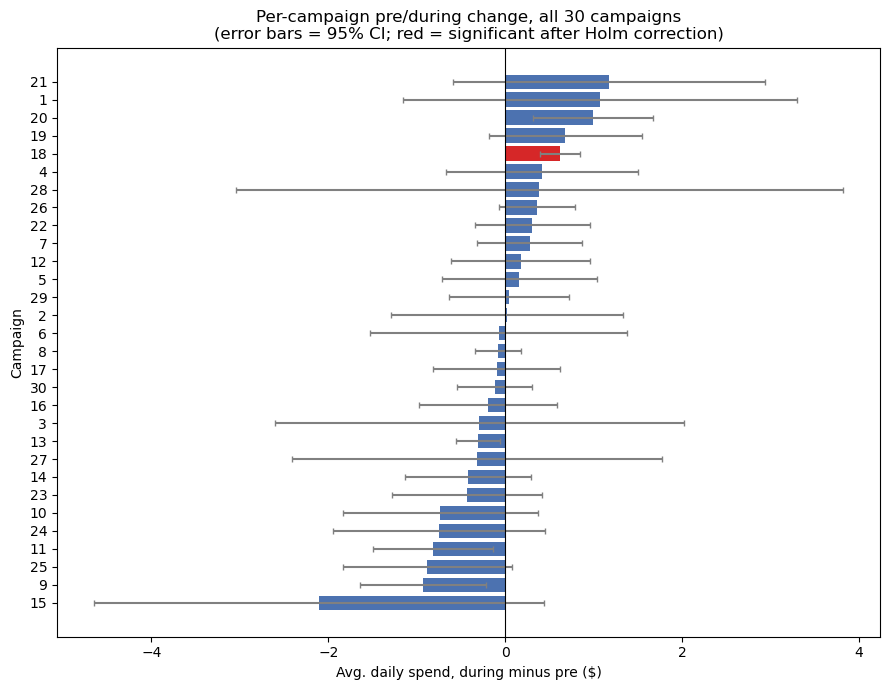

In [12]:
plot_df = (
    campaign_rank[["campaign", "n_households", "avg_daily_diff", "stddev_daily_diff"]]
    .merge(campaign_tests[["campaign", "significant_holm"]], on="campaign")
    .sort_values("avg_daily_diff")
    .reset_index(drop=True)
)
t_crit = stats.t.ppf(0.975, plot_df["n_households"] - 1)
plot_df["ci_half_width"] = t_crit * plot_df["stddev_daily_diff"] / np.sqrt(plot_df["n_households"])

bar_colors = ["#d62728" if sig else "#4C72B0" for sig in plot_df["significant_holm"]]

fig, ax = plt.subplots(figsize=(9, 7))
ax.barh(plot_df["campaign"].astype(str), plot_df["avg_daily_diff"],
        xerr=plot_df["ci_half_width"], color=bar_colors, ecolor="gray", capsize=2)
ax.axvline(0, color="black", linewidth=0.8)
ax.set_xlabel("Avg. daily spend, during minus pre ($)")
ax.set_ylabel("Campaign")
ax.set_title("Per-campaign pre/during change, all 30 campaigns\n(error bars = 95% CI; red = significant after Holm correction)")
plt.tight_layout()

from pathlib import Path
Path("../outputs/figures").mkdir(parents=True, exist_ok=True)
plt.savefig("../outputs/figures/05_campaign_effect_ranking.png", bbox_inches="tight", dpi=300)
plt.show()

## 6. Conclusion

This notebook set out to answer: do coupon campaigns produce a measurable
change in targeted households' spending, or would spending look the same
without them?

Across all 7,208 household-campaign pairs, the within-household comparison (Section 3) found no aggregate change: +$0.01/day, p = 0.844. The between-household comparison (Section 4.1) found targeted households spending about twice as much as non-targeted ones during campaign windows ($9.58 vs. $4.61/day). Section 4.2 showed that the gap was already there before the campaigns: $6.14/day on average in the pre-windows against $6.00/day during them, significant in 29 of 30 campaigns. The retailer targets households that already spend more, and a plain targeted vs. non-targeted comparison mostly measures that choice.

Tested one by one with Holm correction, only campaign 18 (the largest, 1,133 households) shows a pre/during change that survives (+$0.62/day, 95% CI +$0.40 to +$0.84). Once non-targeted households' change over the same windows is subtracted, its difference-in-differences drops to +$0.27/day (CI +$0.01 to +$0.52), which doesn't survive the correction, and no other campaign's difference-in-differences does either. The data doesn't show a clear effect on spending for any single campaign. Campaign 18 is the only candidate worth a closer look, and most of its change was shared by households it didn't target.

These estimates also rest on assumptions, since campaigns weren't randomly assigned: no shared trend for the pre/during design, and equal dollar trends for the difference-in-differences (a proportional seasonal trend would bias the latter downward for the higher-spending targeted group). They describe associations, not proven causal effects. This closes the core dunnhumby analysis (`01`-`05`); the two independent microcases (funnel and A/B testing) don't depend on any table built here.